# Clustering Track — Credit-Card Customer Risk Segmentation
**23CSE301 Machine Learning Capstone — Review 2 (Full Clustering Track)**

**Dataset:** `data/credit_card_clustering/CC GENERAL.csv` (8,950 rows x 18 columns) — the Kaggle *Credit Card Dataset for Clustering* (Arjun Bhasin): real, anonymised usage behaviour of ~9,000 active credit-card holders summarised over 6 months.

**Problem statement:** Segment card holders into groups with similar spending, borrowing and repayment behaviour, **without any labels**, and interpret each segment in terms of **credit risk** (e.g. customers who live on cash advances and only pay the minimum vs. customers who pay their balance in full). This extends the project's *AI Risk Analysis* theme: Regression scores loan risk, Classification flags fraudulent claims, and Clustering discovers risk segments in an existing card portfolio.

**Scope of this notebook (Review 2):**

1. Data loading & audit (shape, dtypes, missing values, duplicates, data-quality checks)
2. Exploratory Data Analysis (distributions, skewness, correlation heatmap, feature relationships)
3. Cleaning (justified missing-value strategy, invalid values, outliers), feature engineering, log-transform, scaling, PCA
4. **K-Means** — Elbow curve (inertia vs. k) + silhouette analysis to choose k
5. **Agglomerative Hierarchical Clustering** — Dendrogram, comparison of `ward` / `complete` / `average` / `single` linkage
6. **Evaluation** — Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index for all algorithms
7. **Visualisation** — PCA 2-D scatter for every algorithm, **t-SNE** plot, silhouette plot
8. Cluster profiling → business / credit-risk interpretation, stability check, saved model

**No ground-truth labels exist** in this dataset, so (as the guidelines require) nothing label-based is used during fitting; segments are validated with internal metrics, stability across random seeds, agreement between the two algorithms, and business interpretability.

**Random seed** `42` is used everywhere for reproducibility.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.dpi'] = 100

DATA_PATH = '../data/credit_card_clustering/CC GENERAL.csv'

## Section A — Dataset Loading & Audit

In [2]:
df = pd.read_csv(DATA_PATH)

print(f'Shape: {df.shape[0]} rows x {df.shape[1]} columns\n')
print('Data types:')
print(df.dtypes.value_counts())
df.head()

Shape: 8950 rows x 18 columns

Data types:
float64    14
int64       3
object      1
Name: count, dtype: int64


,ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


**Column dictionary** (from the dataset's Kaggle description):

| Column | Meaning |
|---|---|
| `CUST_ID` / `ID` | Card-holder identifier (dropped — not a behaviour) |
| `BALANCE` | Balance left on the account to make purchases |
| `BALANCE_FREQUENCY` | How frequently the balance is updated (0–1) |
| `PURCHASES` | Total purchases (= one-off + instalment) |
| `ONEOFF_PURCHASES` / `INSTALLMENTS_PURCHASES` | Largest single-payment purchases / purchases paid in instalments |
| `CASH_ADVANCE` | Cash withdrawn against the card (expensive, high-risk borrowing) |
| `*_FREQUENCY` | Fraction of months with that activity (0–1) |
| `CASH_ADVANCE_TRX` / `PURCHASES_TRX` | Number of cash-advance / purchase transactions |
| `CREDIT_LIMIT` | Credit limit of the card |
| `PAYMENTS` | Amount paid back by the user |
| `MINIMUM_PAYMENTS` | Minimum payments made by the user |
| `PRC_FULL_PAYMENT` | Fraction of months in which the full balance was paid |
| `TENURE` | Months of card service (6–12) |

In [3]:
missing = df.isna().sum()
missing = missing[missing > 0]
print('Columns with missing values:')
print(pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(2)}))

print(f'\nDuplicate rows: {df.duplicated().sum()}')
print(f"Duplicate customer IDs: {df['ID'].duplicated().sum()}")

# Data-quality check: frequency columns are fractions of months and must lie in [0, 1].
freq_cols = [c for c in df.columns if c.endswith('FREQUENCY')]
print('\nValues > 1 in frequency columns (invalid by definition):')
print((df[freq_cols] > 1).sum())

# Consistency check: PURCHASES should equal ONEOFF_PURCHASES + INSTALLMENTS_PURCHASES.
gap = (df['PURCHASES'] - df['ONEOFF_PURCHASES'] - df['INSTALLMENTS_PURCHASES']).abs()
print(f'\nRows where PURCHASES != ONEOFF + INSTALLMENTS (by more than 1 unit): {(gap > 1).sum()}')

print('\nTENURE distribution (months):')
print(df['TENURE'].value_counts().sort_index(ascending=False))

Columns with missing values:
                  missing  percent
CREDIT_LIMIT            1     0.01
MINIMUM_PAYMENTS      313     3.50

Duplicate rows: 0
Duplicate customer IDs: 0

Values > 1 in frequency columns (invalid by definition):
BALANCE_FREQUENCY                   0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              8
dtype: int64

Rows where PURCHASES != ONEOFF + INSTALLMENTS (by more than 1 unit): 19

TENURE distribution (months):
TENURE
12    7584
11     365
10     236
9      175
8      196
7      190
6      204
Name: count, dtype: int64


**Observation:** The dataset has **8,950 customers x 18 columns** (17 numeric behaviour features + the `ID`). There are **no duplicate rows or IDs**. Two columns have missing values: `MINIMUM_PAYMENTS` (**313 rows, 3.5%**) and `CREDIT_LIMIT` (**1 row**). The audit also finds two data-quality problems that a pre-cleaned dataset would not have: **8 customers have `CASH_ADVANCE_FREQUENCY` > 1**, which is impossible for a "fraction of months", and **19 rows where `PURCHASES` does not equal one-off + instalment purchases**. `TENURE` is concentrated at 12 months (85%), so totals for the ~15% of shorter-tenure customers are not directly comparable — this motivates the per-month features in B2.

In [4]:
# Is MINIMUM_PAYMENTS missing at random? Compare the rows where it is missing with the rest.
mp_missing = df['MINIMUM_PAYMENTS'].isna()
print(f'Rows with MINIMUM_PAYMENTS missing: {mp_missing.sum()}')
print(f"  ...of which PAYMENTS == 0: {(mp_missing & (df['PAYMENTS'] == 0)).sum()}")
print(f"Share of PAYMENTS == 0 among rows where MINIMUM_PAYMENTS is present: {(df.loc[~mp_missing, 'PAYMENTS'] == 0).mean():.2%}")
print()
print(df.groupby(mp_missing)[['BALANCE', 'PURCHASES', 'PAYMENTS', 'CREDIT_LIMIT']].median()
        .rename(index={False: 'MINIMUM_PAYMENTS present', True: 'MINIMUM_PAYMENTS missing'}).round(1))

Rows with MINIMUM_PAYMENTS missing: 313
  ...of which PAYMENTS == 0: 240
Share of PAYMENTS == 0 among rows where MINIMUM_PAYMENTS is present: 0.00%

                          BALANCE  PURCHASES  PAYMENTS  CREDIT_LIMIT
MINIMUM_PAYMENTS                                                    
MINIMUM_PAYMENTS present    916.7      375.2     896.3        3000.0
MINIMUM_PAYMENTS missing     16.8      130.4       0.0        3000.0


**Observation:** The missing `MINIMUM_PAYMENTS` values are **not missing at random**. **240 of the 313** belong to customers whose `PAYMENTS` is exactly **0**, while *no* customer with a recorded minimum payment has zero payments. The missing group also has a far lower median balance (17 vs. 917). The gap is therefore structural: a customer who paid nothing has no minimum payment to record. Filling these with the column median (≈295) would invent payments that never happened, so B1 sets them to 0 and uses the median only for the remaining 73 rows.

## Section A — EDA Visualisations

### A2.1 Distribution of every feature

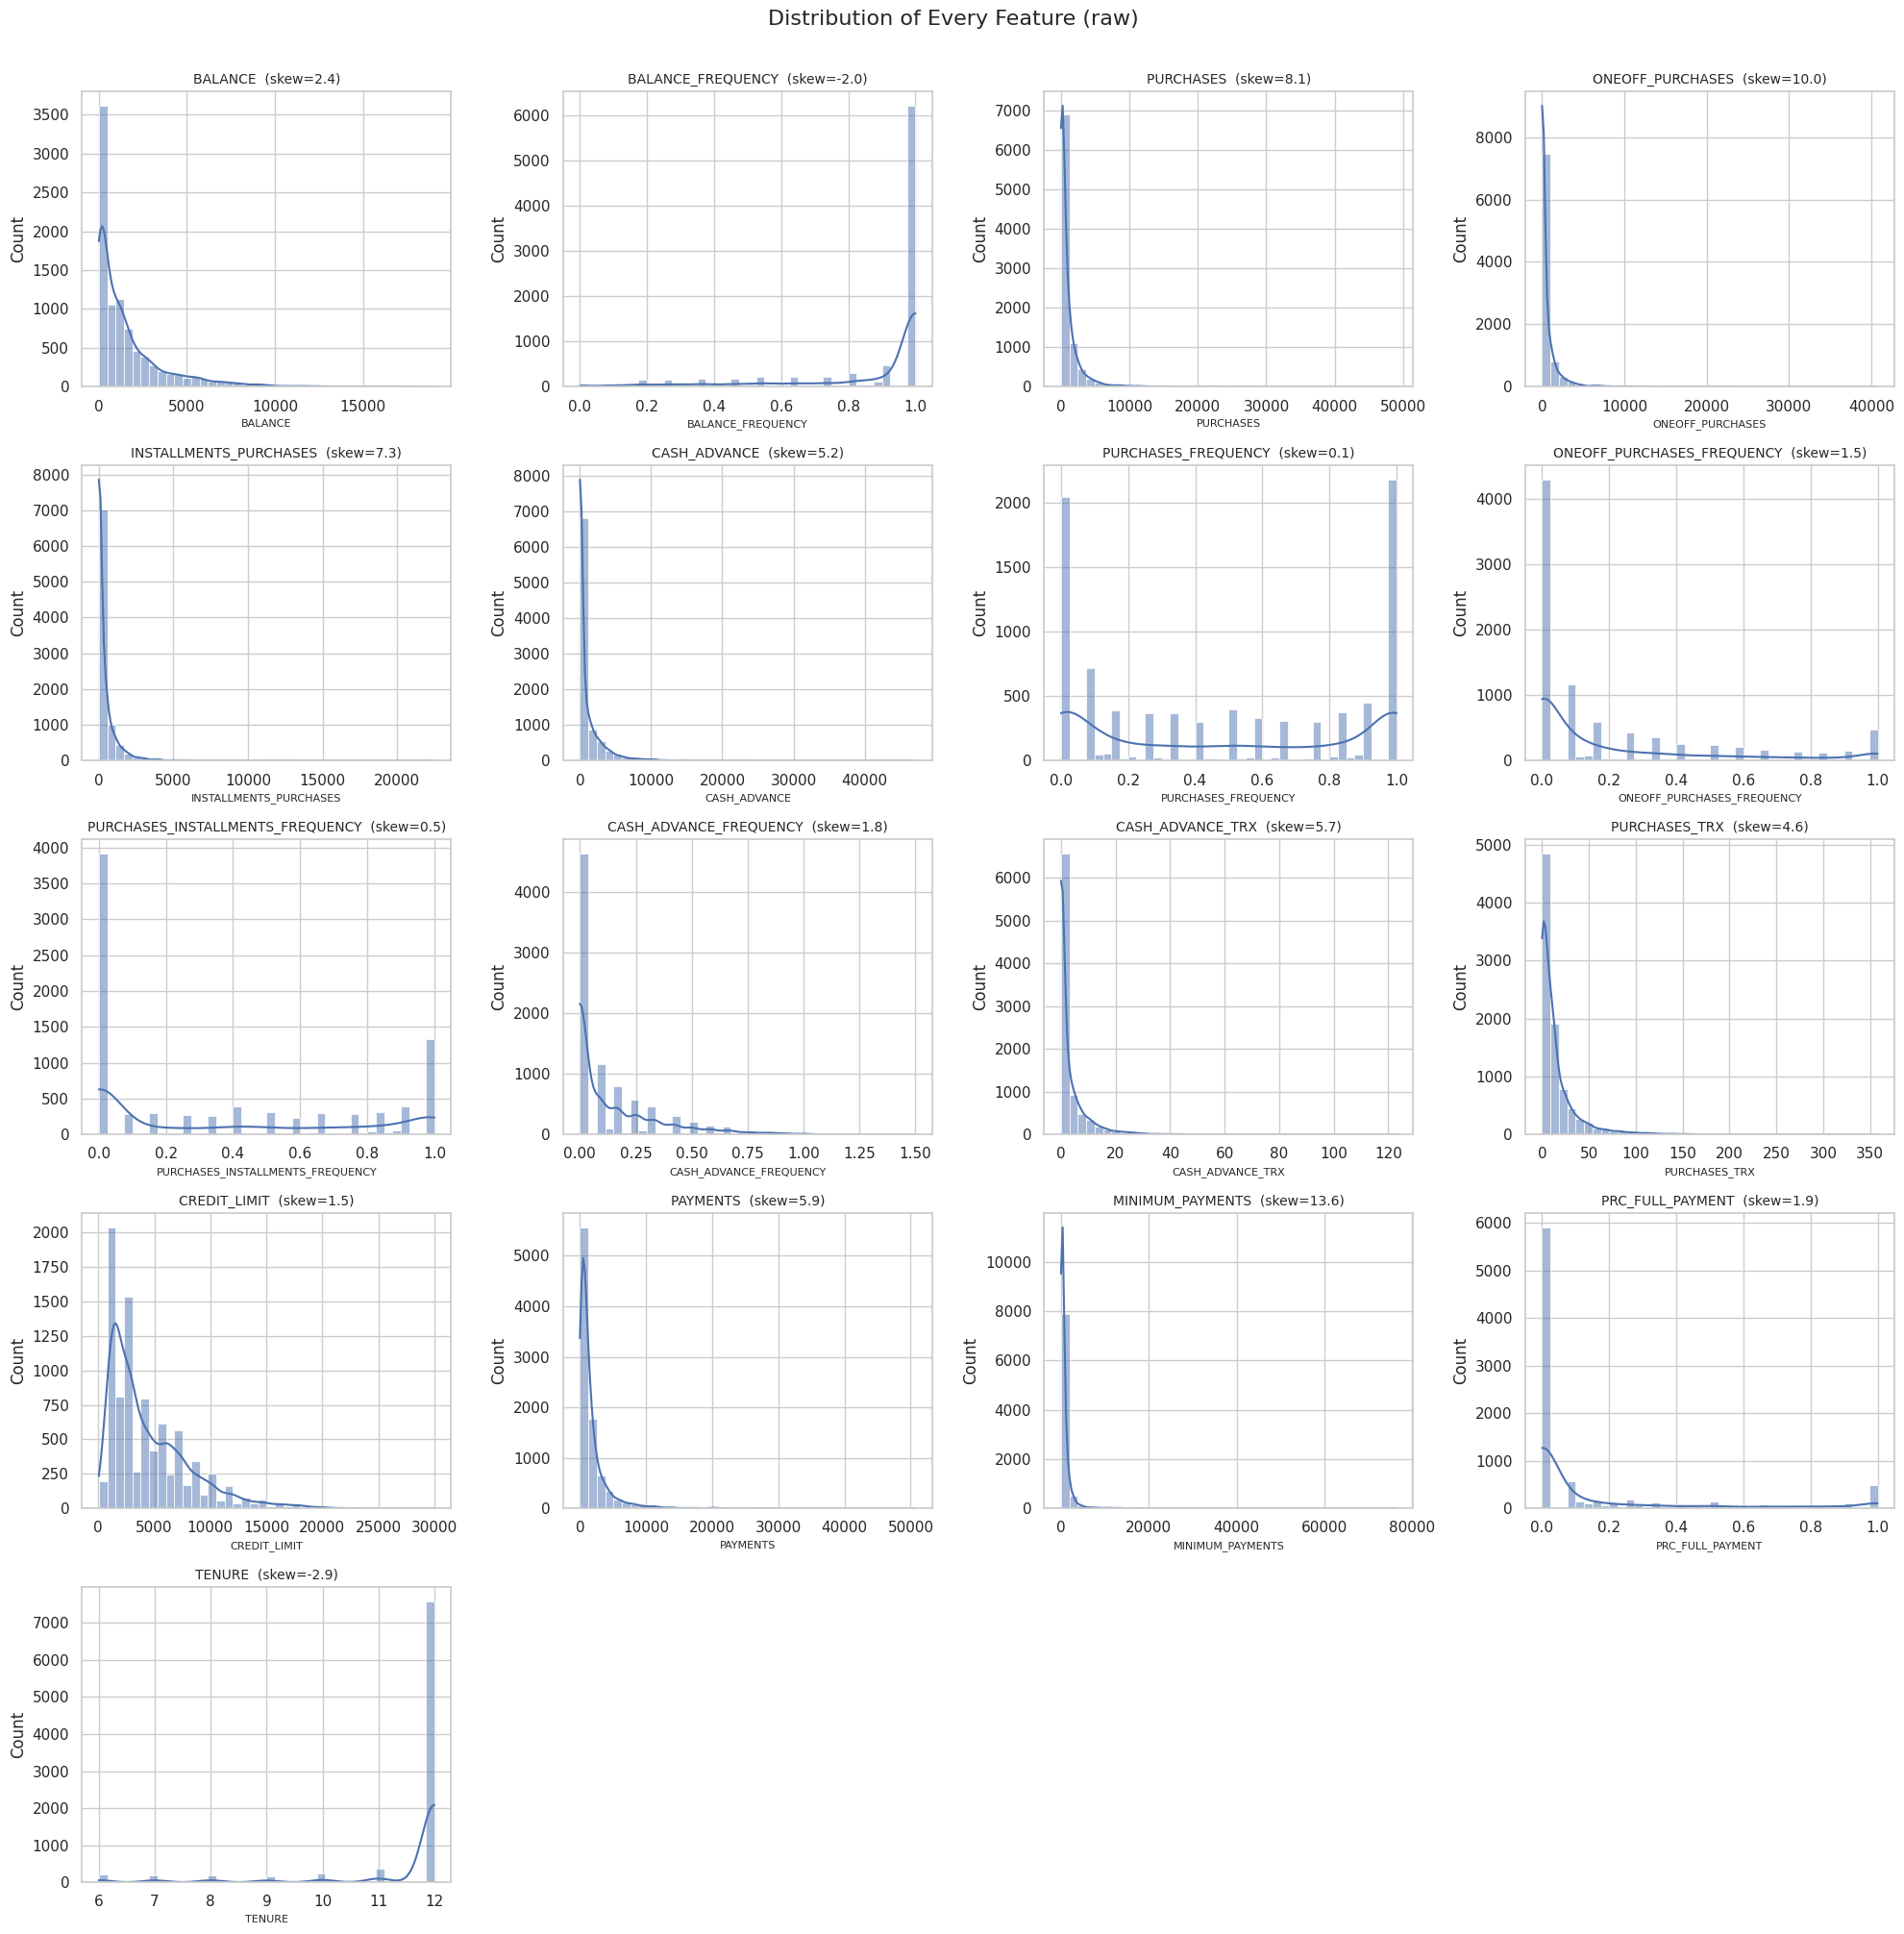

In [5]:
feature_cols = [c for c in df.columns if c != 'ID']

fig, axes = plt.subplots(5, 4, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='#4C72B0', bins=40)
    axes[i].set_title(f'{col}  (skew={df[col].skew():.1f})', fontsize=10)
    axes[i].set_xlabel(col, fontsize=8)
    axes[i].set_ylabel('Count')
for j in range(len(feature_cols), len(axes)):
    fig.delaxes(axes[j])
fig.suptitle('Distribution of Every Feature (raw)', fontsize=16, y=1.005)
plt.tight_layout()
plt.savefig('../models/clu_feature_distributions.png', bbox_inches='tight')
plt.show()

**Observation:** Almost every monetary feature (`PURCHASES`, `ONEOFF_PURCHASES`, `CASH_ADVANCE`, `PAYMENTS`, `MINIMUM_PAYMENTS`) is **extremely right-skewed** (skew 5–14) with a large spike at **zero**: most customers never take a cash advance and many never make one-off purchases. The frequency features are **bimodal** (piled up at 0 and at 1) — customers tend to either always or never use a given feature. `TENURE` and `BALANCE_FREQUENCY` are skewed the other way (most at the maximum). Skews this strong would let a few extreme customers dominate any Euclidean-distance clustering, which is why B3 applies a log transform.